# 04. Forced photometry on a ground-based image

This notebook fits the VIS source models to a ground-based image you supply.
The example is a 200-arcsec SDSS $g$ image centred on RA = 265.8432, Dec = 64.9650.

A ground image can have a more variable PSF and sky than a space image. We
first check its astrometry and PSF against stars in the field. SDSS has
already subtracted a sky estimate, so the first fit makes no additional sky
subtraction. Section 10 demonstrates background subtraction with an injected
sky map.

The SDSS catalog is used only to check the measurements.

**Ground-based inputs** in `examples/data/ground_based/`:

- Science: `SDSS_265.8432_64.9650_g_200_sci.fits`
- Variance: `SDSS_265.8432_64.9650_g_200_var.fits`
- PSF: `SDSS_265.8432_64.9650_g_200_psf.fits` (without a PSF stamp, use a 2-D Gaussian as a placeholder; see section 1)
- Catalog for comparison: `SDSS_265.8432_64.9650_g_200_cat.ecsv`

**Euclid inputs** (VIS science, RMS and flag cutouts, VIS GRID PSF stamps and
the MER source catalog) are downloaded in section 2 on the first run and
cached under `examples/native_data/`, as in the other notebooks.

In [1]:
# Locate the package when running from either notebook directory.
import os, sys
from pathlib import Path
PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                     if (p / "src/euclid_phot").is_dir()), None)
if PROJECT_ROOT is None:
    raise RuntimeError("Run this notebook from the repository.")
if "euclid_phot" in sys.modules:
    loaded_from = Path(sys.modules["euclid_phot"].__file__).resolve()
    if loaded_from != (PROJECT_ROOT / "src/euclid_phot/__init__.py").resolve():
        raise RuntimeError("Restart the kernel to load this repository's package.")
sys.path.insert(0, str(PROJECT_ROOT / "src"))
os.environ.setdefault("EUCLID_PHOT_DATA_DIR", str(PROJECT_ROOT / "examples/native_data"))

from dataclasses import replace
import time

import numpy as np
import matplotlib.pyplot as plt
from astropy import units as u
from astropy.table import Table
from astropy.io import fits
from astropy.wcs import WCS
from IPython.display import display

from euclid_phot import ground_based as gb

DATA_DIR = Path(os.environ["EUCLID_PHOT_DATA_DIR"])  # Euclid cache
GROUND_DIR = PROJECT_ROOT / "examples/data/ground_based"
OUTPUT_DIR = PROJECT_ROOT / "examples/output/ground_based"
N_WORKERS = 8

## 1. Input image
#### The user should place their ground based data (science map,  uncertainty map, PSF stamp) to `GROUND_DIR`
#### then read the file to define the variable `sci_data`, `sci_header` (for the `sci_wcs`), `unc_data`, `psf_data`, and the `science_unit `. 



In [2]:
# define the data 
sci_data, sci_header = fits.getdata(GROUND_DIR / "SDSS_265.8432_64.9650_g_200_sci.fits", header = True)
unc_data = np.sqrt( fits.getdata(GROUND_DIR / "SDSS_265.8432_64.9650_g_200_var.fits") )
psf_data = fits.getdata(GROUND_DIR / "SDSS_265.8432_64.9650_g_200_psf.fits")
sci_wcs = WCS(sci_header).celestial

print(sci_header['BUNIT'])
# define the unit 
science_unit = u.nanomaggy


# example of generation a psf_data : 

pixel_scale_arcsec = ( np.sqrt(abs(np.linalg.det(sci_wcs.pixel_scale_matrix))) * 3600 )

psf_data_filler = gb.gaussian_psf( fwhm_arcsec=1.4,  # replace with the image's measured seeing
                                   pixel_scale_arcsec=pixel_scale_arcsec,  
                                 ) 
# Then this psf_data_filler has the same format as psf_data 

nanomaggy/pixel


### Take a look at the data



505 × 505 pixels; 0.396″/pixel; band ground
Footprint ≈ 200.0″ × 200.0″
PSF stamp (51, 51), sum 1.000000


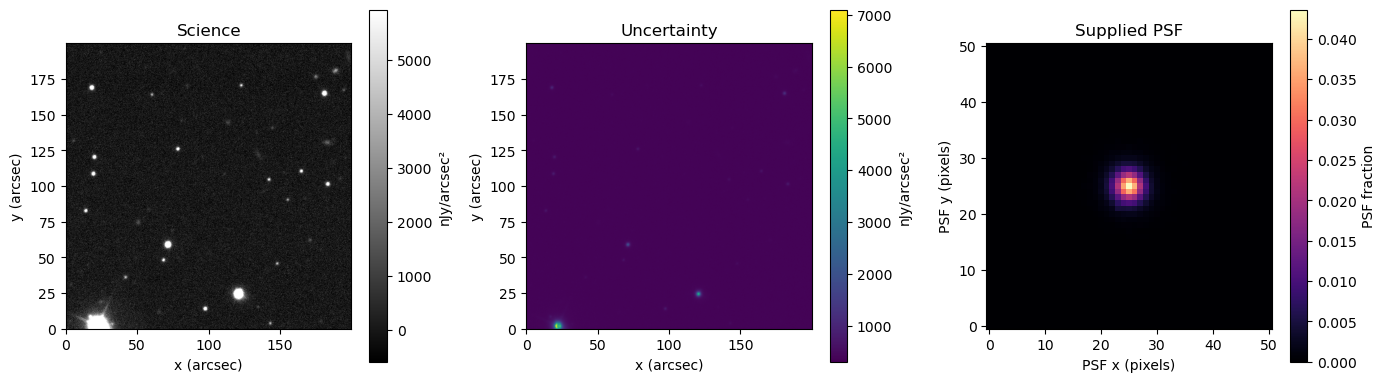

In [3]:
inputs = gb.make_image(sci_data, unc_data, psf_data, science_unit, sci_wcs)
image = inputs.image
ny, nx = image.science_njy.shape
print(f"{nx} × {ny} pixels; {inputs.pixel_scale_arcsec:.3f}″/pixel; band {image.band}")
print(f"Footprint ≈ {nx*inputs.pixel_scale_arcsec:.1f}″ × {ny*inputs.pixel_scale_arcsec:.1f}″")
print(f"PSF stamp {image.psf.shape}, sum {image.psf.sum():.6f}")
gb.show_inputs(inputs)
plt.show()

## 2. Euclid VIS image and MER sources

This cell reuses the VIS science, RMS, flag, GRID PSF and MER catalog cached in `DATA_DIR`, and downloads whatever is missing. The VIS box covers the ground image plus a small margin (220 arcsec here). We show VIS next to SDSS, with the MER sources as blue circles.

MER: local cache /Users/shemmati/Desktop/euclid-forced-photometry/examples/native_data/mer_catalog_265.8432_64.9650_220.fits
VIS science/RMS/flag: ready
VIS GRID PSF: ready
Center: 265.8432°, +64.9650°; VIS box: 220″
MER sources: 1448; catalog: /Users/shemmati/Desktop/euclid-forced-photometry/examples/native_data/mer_catalog_265.8432_64.9650_220.fits


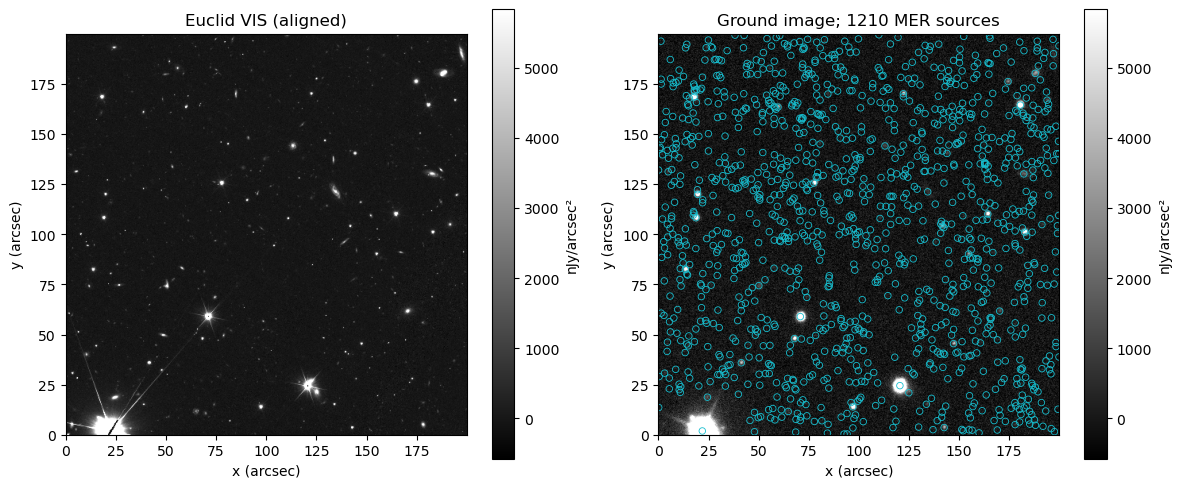

In [4]:
euclid = gb.prepare_euclid(image, DATA_DIR)
print(f"Center: {euclid.ra:.4f}°, {euclid.dec:+.4f}°; VIS box: {euclid.size_arcsec:.0f}″")
print(f"MER sources: {len(euclid.mer)}; catalog: {euclid.mer_path}")
gb.show_scene(inputs, euclid)
plt.show()

## 3. Check the image WCS

Match bright, isolated stars in the ground image to MER stars, and use Astropy to refit the WCS from their centroids. 

Matched stars: 16
Median offset: 0.233″ before → 0.128″ after


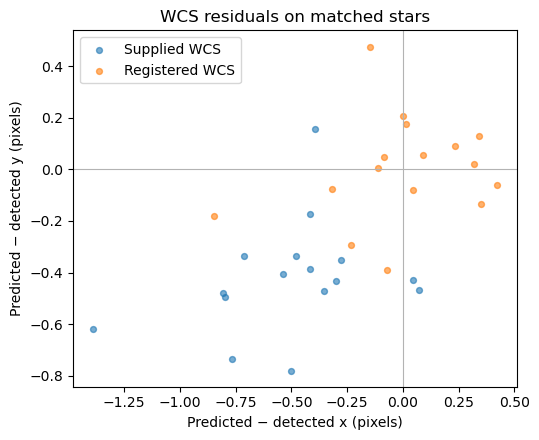

In [5]:
registration = gb.register_image(image, euclid.mer, min_matches=10)
print(f"Matched stars: {registration.n_used}")
print(f"Median offset: {registration.median_before_arcsec:.3f}″ before → "
      f"{registration.median_after_arcsec:.3f}″ after")
image = replace(image, wcs=registration.wcs)
inputs = replace(inputs, image=image)
gb.show_registration(registration)
plt.show()

## 4. Check PSF vs. stars

Here we compare the bright, isolated stars with the supplied PSF.  There are 10 selected stars in our example field, and we show 4 of them as demonstration.  The light curve of PSF matches with the stars within 3~4" before the sky noise dominating the edges.  

Usable stars: 10; recommendation: supplied
FWHM: supplied 5.61 pixels; image stars 6.03 pixels
We have 10 stars.


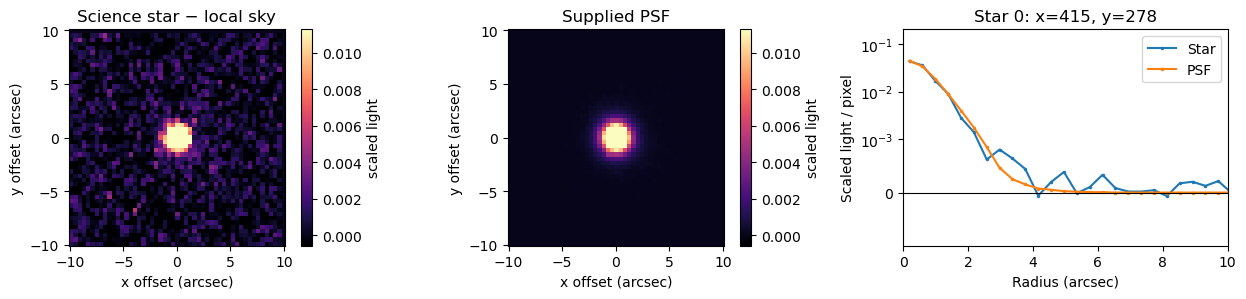

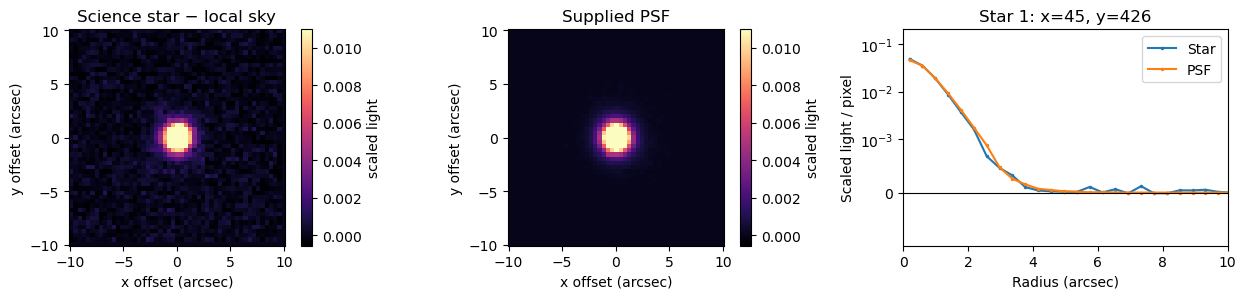

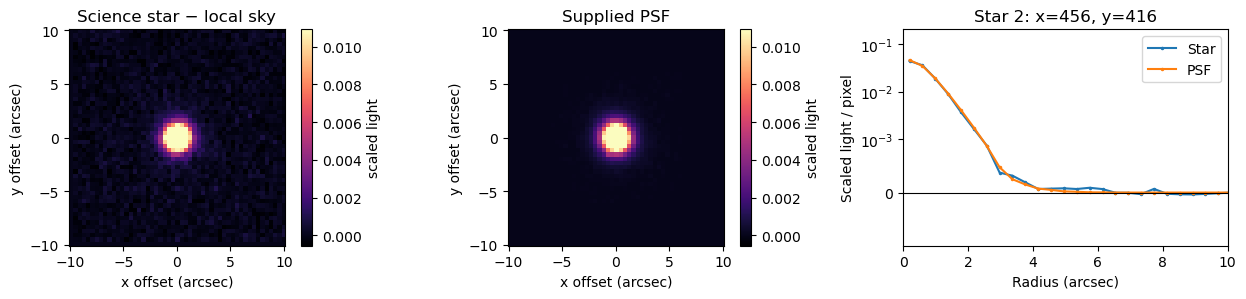

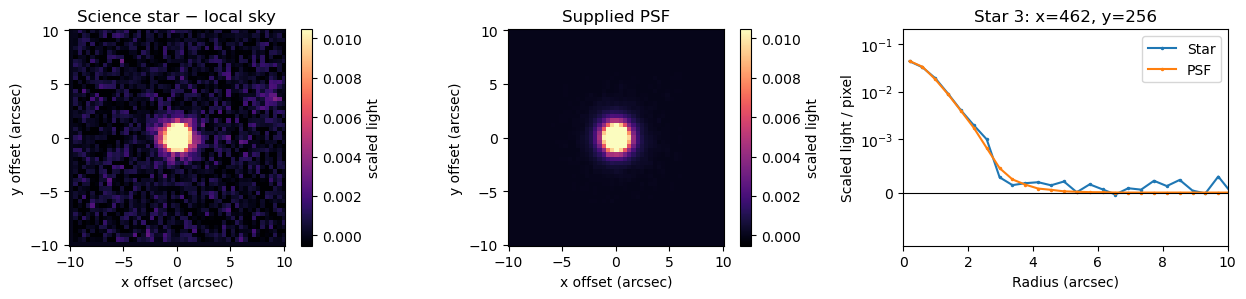

In [6]:
psf_check = gb.assess_psf(image, registration)
print(f"Usable stars: {len(psf_check.stars)}; recommendation: {psf_check.recommendation}")
if psf_check.empirical_psf is not None:
    print(f"FWHM: supplied {psf_check.supplied_fwhm_pix:.2f} pixels; "
          f"image stars {psf_check.observed_fwhm_pix:.2f} pixels")
    
print(f"We have {len(psf_check.stars)} stars.")
for i in range(4):
    gb.show_psf_stars(image, psf_check, star_index=i)
    plt.show()

### Choose the ground-image PSF

Choose the PSF for the forced photometry fitting. `"supplied"` uses the PSF stamp read in section 1; `"nearest_star"` uses the closest usable image star to each fitted region, after local sky removal and smoothing its noisy outer wings. The star numbers in the figures above identify stars you can exclude. If the PSF changes within one fitted region, a single stamp there remains an approximation.

In [7]:
PSF_MODE = "supplied"      # or "nearest_star" , "avg_star"
EXCLUDE_PSF_STARS = ()     # row numbers from the figure above, e.g. (1, 3)
print("Ground PSF mode:", PSF_MODE)

Ground PSF mode: supplied


## 5. Fit VIS source morphology

Using a wrapper of `euclid_phot.run_forced_photometry`: MER positions, the model-selection tree, local GRID PSFs, and the VIS bright-star mask. 

In [8]:
vis_start = time.perf_counter()
vis = gb.fit_vis(euclid, DATA_DIR, n_workers=N_WORKERS)
print(f"VIS morphology fit: {(time.perf_counter() - vis_start) / 60:.1f} min")
print(f"VIS models: {len(vis.sources)}; good VIS fluxes: {np.count_nonzero(vis.flux_quality)}")
print("Model classes:", dict(zip(*np.unique(vis.chosen_models, return_counts=True))))

[1/7] using caller-supplied MER catalog (1448 rows; no query, no cache)
[2/7] discover mosaics for VIS (lazy; only on a cache miss)
[3/7] fetch cutouts: VIS
[4/7] build per-band PSFs (GRID-PSF, radius=165")
[5/7] build Tractor image + source models on VIS
[5a] STARSIGNAL bright-star mask: 247484 pixels (5.11%) excluded from the VIS fit


[6/7] VIS fit (free, forced-photometry)


VIS morphology fit: 2.8 min
VIS models: 1447; good VIS fluxes: 1444
Model classes: {np.str_('DevGalaxy'): np.int64(189), np.str_('ExpGalaxy'): np.int64(696), np.str_('FixedCompositeGalaxy'): np.int64(165), np.str_('PointSource'): np.int64(240), np.str_('SersicGalaxy'): np.int64(139), np.str_('SimpleGalaxy'): np.int64(18)}


## 6. Fit ground-image fluxes

Using a wrapper of `euclid_phot.run_forced_photometry` to fit their ground-image fluxes with Tractor, together with the chosen PSF and the supplied uncertainty map. 

Current example set `BACKGROUND_METHOD="none"` since the SDSS image is background-free. The `"sep"` option uses SEP background subtraction method before fitting. 

In [9]:
BACKGROUND_METHOD = "none"  # or "sep"
ground_start = time.perf_counter()
fit = gb.fit_ground(image, vis, background_method=BACKGROUND_METHOD,
                    psf_mode=PSF_MODE, psf_assessment=psf_check,
                    excluded_psf_stars=EXCLUDE_PSF_STARS)
print(f"Ground flux fit: {time.perf_counter() - ground_start:.1f} s")
output = OUTPUT_DIR / f"{euclid.ra:.4f}_{euclid.dec:.4f}_{image.band}"
cat_path, image_path = gb.save_fit(fit, output)
print(f"Measured {len(fit.catalog)} sources in {fit.catalog.meta['NTILES']} region(s)")
print("Catalog:", cat_path)
print("Image, model, sky and residual:", image_path)
display(fit.catalog["object_id", "model_class", "flux_njy", "fluxerr_njy", "in_image"][:8])

Ground flux fit: 13.6 s
Measured 1311 sources in 1 region(s)
Catalog: /Users/shemmati/Desktop/euclid-forced-photometry/examples/output/ground_based/265.8432_64.9650_ground/forced_catalog.ecsv
Image, model, sky and residual: /Users/shemmati/Desktop/euclid-forced-photometry/examples/output/ground_based/265.8432_64.9650_ground/fit_images.fits


object_id,model_class,flux_njy,fluxerr_njy,in_image
int64,str20,float64,float64,bool
2657813573649421046,SersicGalaxy,18374110.0788341,9477.554976400841,True
2658172968649564060,SersicGalaxy,567670.6384029641,1678.4062468611883,True
2657932160649697516,SersicGalaxy,2092948.021569277,3401.538274586128,True
2657869751649630978,PointSource,65449.80277114259,724.0856098911033,True
2658832888649881954,PointSource,197648.62708303938,1061.3460814386215,True
2658607700649591023,PointSource,47856.79164360761,660.8662651205,True
2658480802649830124,PointSource,38871.16211728626,624.5885067420006,True
2658344049649407820,PointSource,45587.2556982211,652.160239687373,True


## 7. Compare with an independent catalog


Comparing the forced photometry results to the SDSS catalog. We show the sources matched within 0.7", SNR > 5 in blue (stars) or orange (galaxies), and the rest of the sources in gray. 

("reference_clean" is the SDSS catalog column "clean" for objects that pass its photometry quality checks ; Note that there are some sources outside the range of 13~27 mag)

Clean SDSS matches: 42 / 94 catalog rows
star: N=25, median forced/SDSS=0.990
galaxy: N=17, median forced/SDSS=0.996


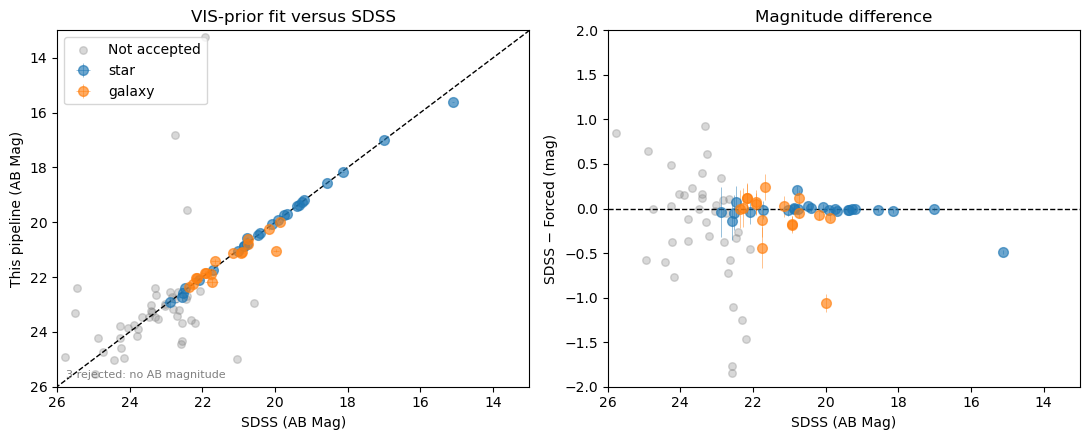

In [10]:
reference = Table.read(GROUND_DIR / "SDSS_265.8432_64.9650_g_200_cat.ecsv")
comparison = gb.compare_sdss_g(fit.catalog, reference)

sdss_snr = comparison["reference_flux_njy"]/comparison["reference_fluxerr_njy"]
forced_snr = comparison["forced_flux_njy"]/ comparison["forced_fluxerr_njy"]
comparison["accepted"] = (
    (np.asarray(comparison["reference_clean"], int) == 1)
    &(np.asarray(comparison["separation_arcsec"], float) < 0.7)
    & ( sdss_snr > 5)
    & ( forced_snr > 5)   
    )
accepted = comparison[np.asarray(comparison["accepted"], bool)]
print(f"Clean SDSS matches: {len(accepted)} / {len(reference)} catalog rows")
for kind in ("star", "galaxy"):
    rows = accepted[accepted["source_type"] == kind]
    if len(rows):
        ratio = rows["forced_flux_njy"] / rows["reference_flux_njy"]
        print(f"{kind}: N={len(rows)}, median forced/SDSS={np.median(ratio):.3f}")
comparison.write(output / "catalog_comparison.ecsv", overwrite=True)
gb.show_catalog_comparison(comparison)
plt.show()

## 8. Inspect fitted sources and residuals

Here we take a look at the good sources, from bright to faint, showing VIS, ground science, the Tractor model, and science minus model. 


Weighted residual RMS: 2.78


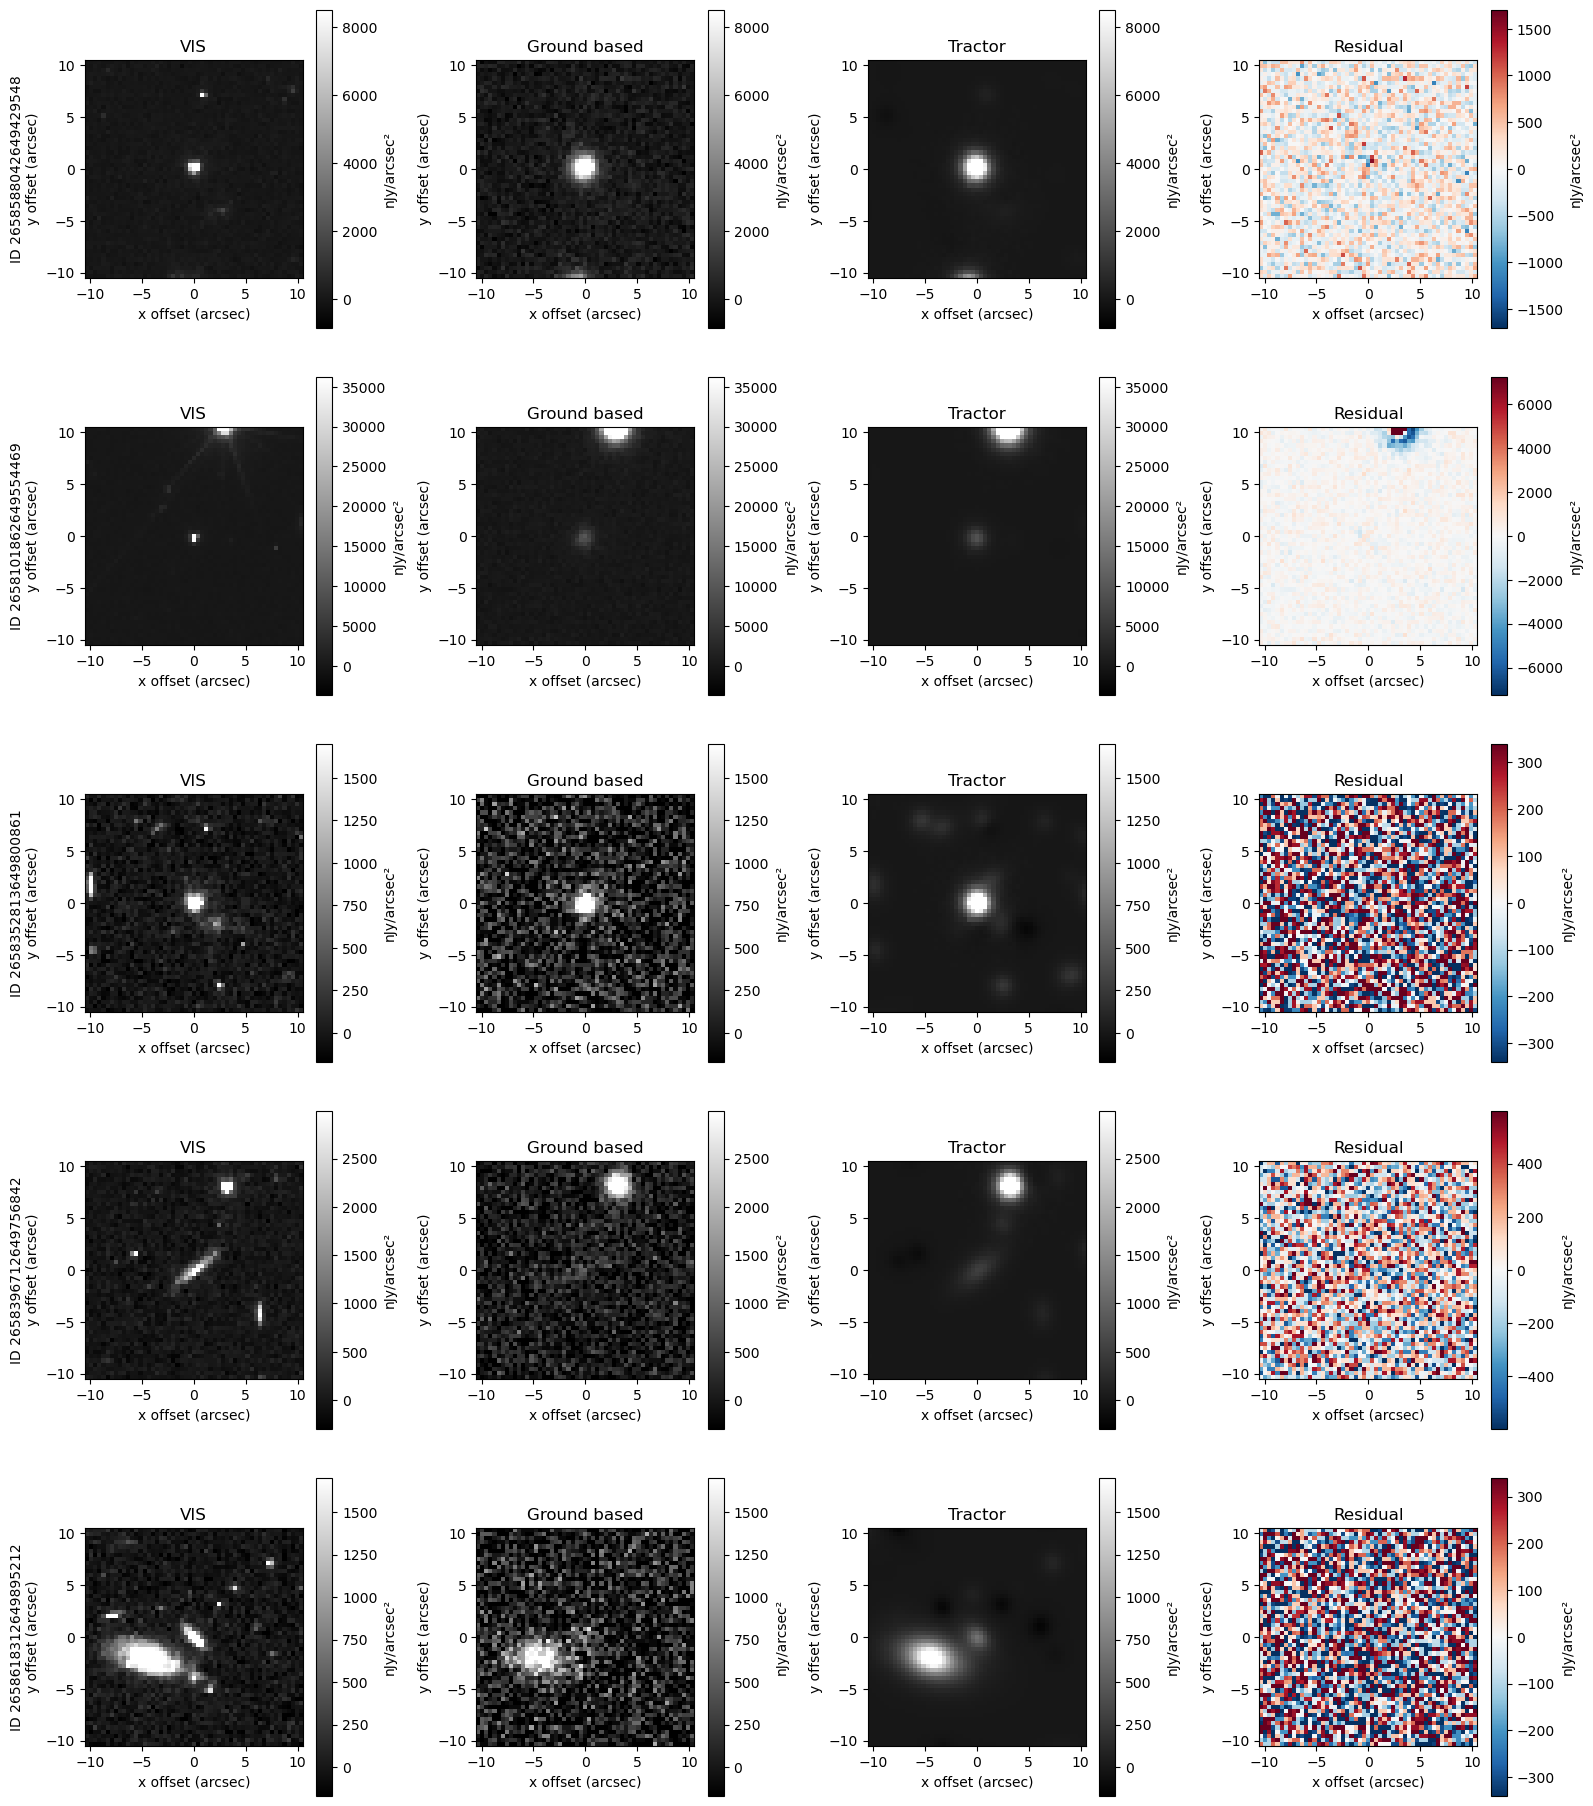

In [11]:
good = image.invvar_njy > 0
weighted_rms = np.sqrt(np.mean(fit.residual[good]**2 * image.invvar_njy[good]))
print(f"Weighted residual RMS: {weighted_rms:.2f}")
INSPECT_VMIN = None  # nJy/arcsec²; e.g. -50
INSPECT_VMAX = None  # nJy/arcsec²; e.g. 500
gb.show_fit_cutouts(fit, euclid.vis_cutout, size_arcsec=20, n_sources=5,
                    vmin=INSPECT_VMIN, vmax=INSPECT_VMAX)
plt.show()

## 9. Inspect mismatches

Here we show the mismatched objects, where the disagreements |SDSS − forced| > 0.4 mag.  There are three bright cases:  (1) galaxies at the edge of the image (2) VIS saturated star (3) galaxies with lower SNR in SDSS.

Mismatches: 3; forced-flux underestimates: 3


euclid_object_id,source_type,sdss_minus_forced_mag,separation_arcsec
int64,str6,float64,float64
2658996460649931001,galaxy,-1.0573895263331876,0.029490987653060702


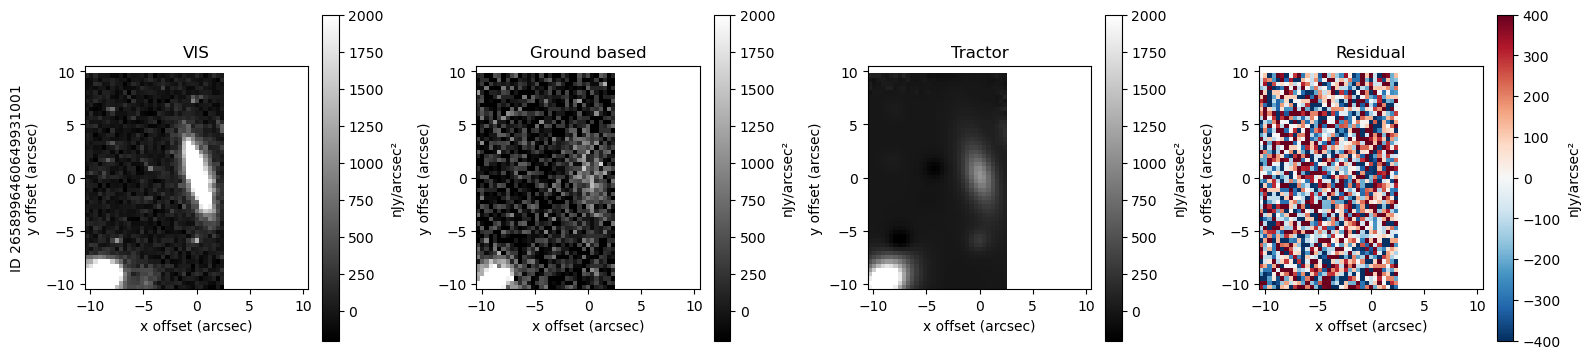

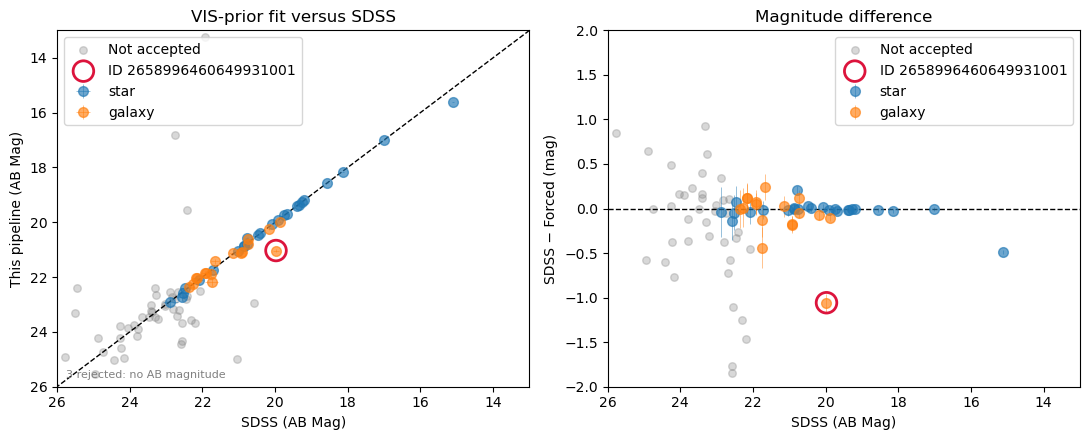

euclid_object_id,source_type,sdss_minus_forced_mag,separation_arcsec
int64,str6,float64,float64
2657932160649697516,star,-0.4881380671716492,0.2979963457960167


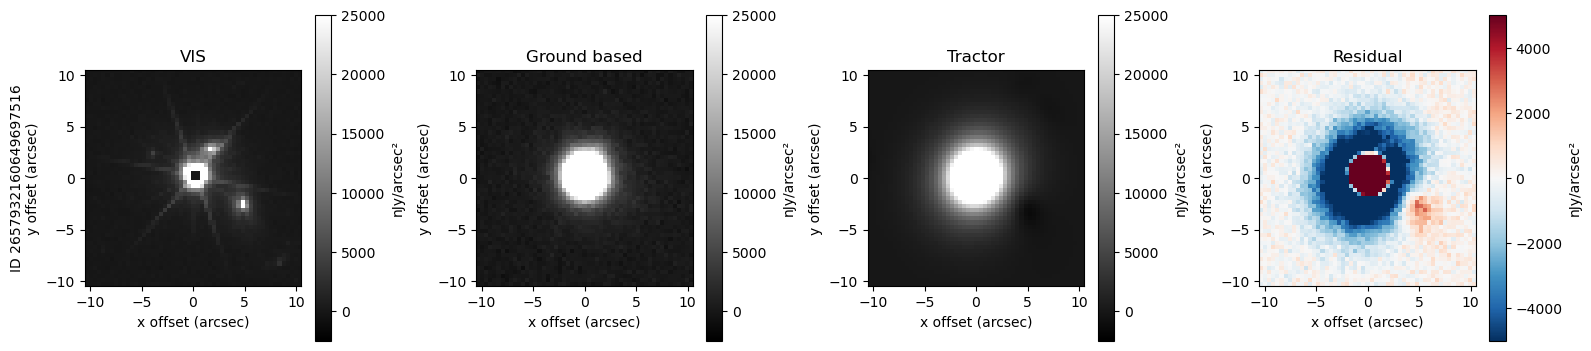

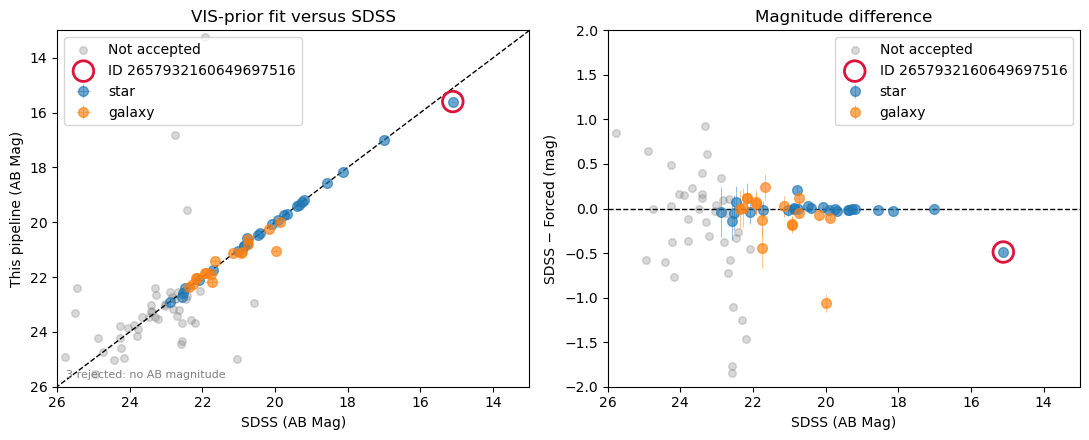

euclid_object_id,source_type,sdss_minus_forced_mag,separation_arcsec
int64,str6,float64,float64
2658396712649756842,galaxy,-0.4376617962926983,0.18331698603436097


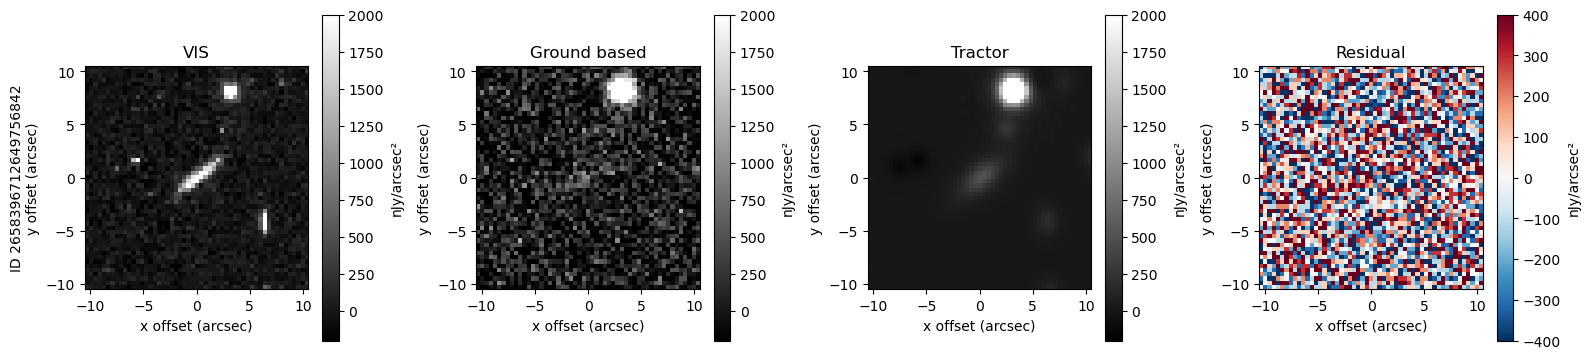

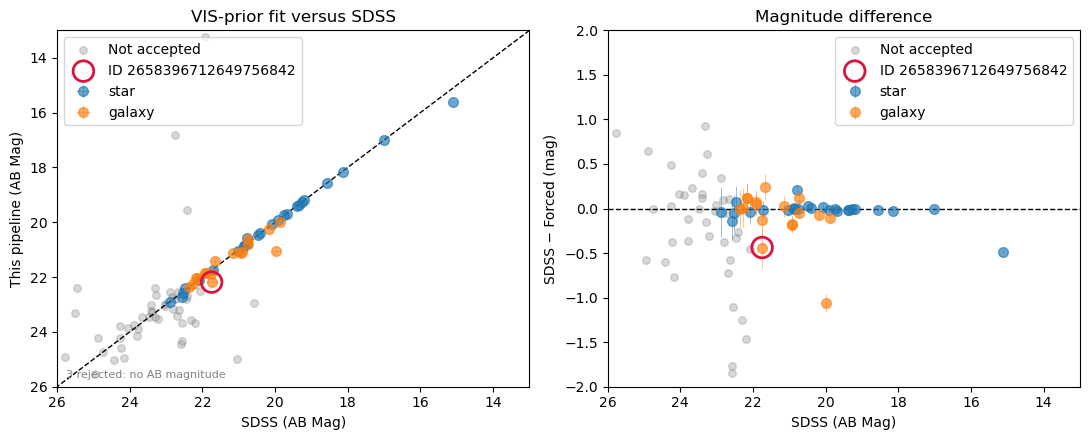

In [12]:
ref_flux = np.asarray(accepted["reference_flux_njy"].data, dtype=float)
forced_flux = np.asarray(accepted["forced_flux_njy"].data, dtype=float)
sdss_minus_forced = 2.5 * np.log10(forced_flux / ref_flux)
mismatch_rows = np.flatnonzero((np.abs(sdss_minus_forced) > 0.4))
mismatch_rows = mismatch_rows[np.argsort(np.abs(sdss_minus_forced[mismatch_rows]))[::-1]]
mismatches = accepted[mismatch_rows]
mismatches["sdss_minus_forced_mag"] = sdss_minus_forced[mismatch_rows]
print(f"Mismatches: {len(mismatches)}; forced-flux underestimates: "
      f"{np.count_nonzero(mismatches['sdss_minus_forced_mag'] < -0.4)}")

# One vmax per mismatch, in the order listed below (nJy/arcsec²).
vmaxs = [ 2000, 25000,2000,]

for i, vmax in enumerate(vmaxs):
    one = mismatches[i:i+1]
    object_id = int(one["euclid_object_id"].data[0])
    display(one["euclid_object_id", "source_type", "sdss_minus_forced_mag",
                "separation_arcsec"])
    gb.show_fit_cutouts(
        fit, euclid.vis_cutout, size_arcsec=20,
        object_ids=[object_id],
        vmin=None, vmax=vmax)
    plt.show()
    gb.show_catalog_comparison(comparison, highlight_object_id=object_id)
    plt.show()


## 10. Test sky subtraction with an injected background

In this section we demonstrate the background subtraction. We add an artificial second-order 2D polynomial and uniform noise as our sky.  Then we run the forced photometry pipeline with or without the background subtraction, and compare the results with the background-free forced photometry fluxes. 

The top row shows the **injected sky**, the SEP estimated sky, and SEP minus the smooth polynomial (this is the extra modeled background due to the scattered light of stars). The bottom row shows the fit residuals before and after background subtraction. The last panel compares both results comparing with the forced-photometry results fitted from the background-free image.  

Several objects report lower fluxes due to the removal of the star scattering lights. Note that the SEP may oversubtract the sky due to the contribution of the scattering lights.

Two injected-image fits: 31.9 s
Injected polynomial sky: 24.5 to 105.0 nJy/pixel; uniform noise: -50.0 to 50.0 nJy/pixel


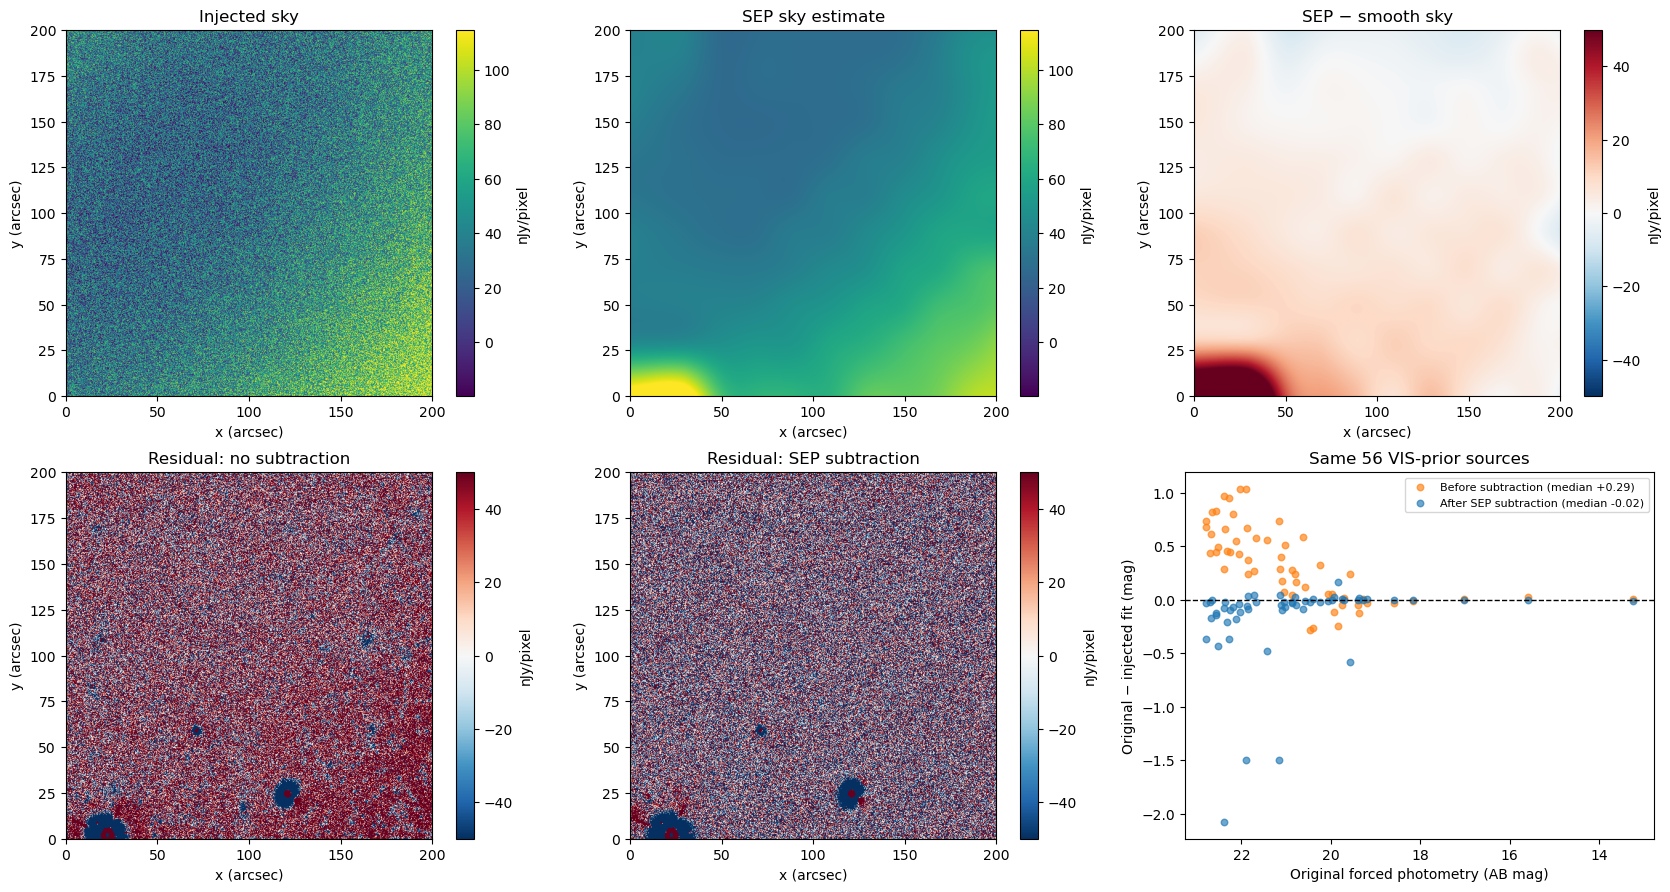

In [13]:
rng = np.random.default_rng(2026)
yy, xx = np.indices(image.science_njy.shape, dtype=float)
xx = (xx - (nx - 1) / 2) / ((nx - 1) / 2)
yy = (yy - (ny - 1) / 2) / ((ny - 1) / 2)
mock_sky = 30 + 18*xx - 12*yy + 15*xx**2 - 16*xx*yy + 14*yy**2
extra_noise = rng.uniform(-50,50,  image.science_njy.shape)
injected_ivar = np.zeros_like(image.invvar_njy)
valid = image.invvar_njy > 0
injected_ivar[valid] = 1 / (1 / image.invvar_njy[valid])
injected_image = replace(image,
    science_njy=image.science_njy + mock_sky + extra_noise,
    invvar_njy=injected_ivar)

sky_test_start = time.perf_counter()
no_sky = gb.fit_ground(
    injected_image, vis, background_method="none", psf_mode=PSF_MODE,
    psf_assessment=psf_check, excluded_psf_stars=EXCLUDE_PSF_STARS)
sep_sky = gb.fit_ground(
    injected_image, vis, background_method="sep", psf_mode=PSF_MODE,
    psf_assessment=psf_check, excluded_psf_stars=EXCLUDE_PSF_STARS)
print(f"Two injected-image fits: {time.perf_counter() - sky_test_start:.1f} s")
print(f"Injected polynomial sky: {mock_sky.min():.1f} to {mock_sky.max():.1f} nJy/pixel; "
      f"uniform noise: {extra_noise.min():.1f} to {extra_noise.max():.1f} nJy/pixel")
gb.show_sky_injection_test(
    mock_sky + extra_noise, fit, no_sky, sep_sky, smooth_sky=mock_sky,
    limit_njy_per_pixel=50)
plt.show()
